# Sampling and Distributions

## *Workshop 5*  [![Open In Colab](https://github.com/oballinger/BASC0005/blob/main/colab-badge.png?raw=1)](https://colab.research.google.com/github/oballinger/BASC0005/blob/main/notebooks/W05.%20Distributions%20and%20Basic%20Statistics.ipynb)

For the next few weeks we'll be working with an extract of the U.S. Census Bureau's [Current Population Survey (CPS)](https://www.census.gov/programs-surveys/cps.html): a large, monthly household survey that is the source of official U.S. statistics on employment, earnings and union membership.

This workshop follows the lecture: we start with **where the data came from** (populations, samples, selection bias), then **summarise** it, and then use the **Central Limit Theorem** and the **standard error** to see how much a single sample can tell us about a population.

### Aims

- Tell a **population** from a **sample**, and spot **selection bias**
- Choose appropriate summary statistics (mean, median, mode, variance, standard deviation) for different variables
- Plot and interpret distributions
- Build intuition for the **Central Limit Theorem** by simulation, using union membership (as in the lecture)
- Use the **standard error** and the 68-95-99.7 rule

The workshop takes roughly two hours.

## Setup

We'll use `pandas` for data, `numpy` for maths and random numbers, and `matplotlib`/`seaborn` for plots.

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

sns.set_theme(style="white", font_scale=1.2)
plt.rcParams["figure.figsize"] = (10, 5)

# Fix the random seed, so your numbers match the ones on the website.
# Change the seed (or delete it) to see how the results vary from run to run.
np.random.seed(42)

In [64]:
cps = pd.read_csv("https://storage.googleapis.com/qm2/wk7/cps.csv")
cps.head()

,year,state,age,sex,race,sch,ind,union,incwage,realhrwage,occupation
0,1990,36,58,1,3,12.0,871,0.0,14200.0,12.269874,Office and Admin Support
1,2009,5,28,1,1,12.0,8660,1.0,17680.0,8.635149,Office and Admin Support
2,1990,36,37,1,1,14.0,380,1.0,28000.0,21.169851,.
3,1990,6,34,1,1,18.0,740,1.0,27500.0,20.447746,Computer and Math Technicians
4,1981,51,38,1,4,13.0,798,NaN,17000.0,18.892282,Managers


The dataframe has one row per person and these columns:

| column | meaning |
|---|---|
| `year` | survey year |
| `state` | state (FIPS code) |
| `age` | age in years |
| `sex` | 1 = male, 2 = female |
| `race` | 1 = White non-Hispanic, 2 = Black non-Hispanic, 3 = Hispanic, 4 = Other non-Hispanic |
| `sch` | years of schooling (12 = high school, 13 = some college, 14 = associate's, 16 = BA, 18 = advanced degree) |
| `ind` | [industry code](https://www.census.gov/naics/) |
| `union` | 0 = not asked (N/A), 1 = not covered by a union, 2 = member of a labour union, 3 = covered by a union but not a member |
| `incwage` | annual wage and salary income ($) |
| `realhrwage` | real hourly wage ($) |
| `occupation` | occupation group (`.` = missing) |

## 1. Populations, samples and selection bias

In the lecture we met Abraham Wald and the bombers: the Navy's data only contained planes that **made it back**, so the bullet holes showed where a plane *could* be hit and survive. The lesson: before computing anything, ask **how did this row end up in my dataset?**

- A **population** is the set of all relevant measurements (e.g. all U.S. workers).
- A **sample** is a group of observations drawn in some way from that population (e.g. the people the CPS interviewed).
- If the sample is not drawn at random, we risk **selection bias**; **survivorship bias** is a special case.

The CPS is a carefully designed random sample of households. But *this extract* has also been filtered by whoever prepared it. Let's check who is actually in it.

In [65]:
cps[["year", "age", "incwage", "realhrwage"]].agg(["min", "max"])

,year,age,incwage,realhrwage
min,1981,25,15.0,2.00000
max,2013,64,1259999.0,294610.96875


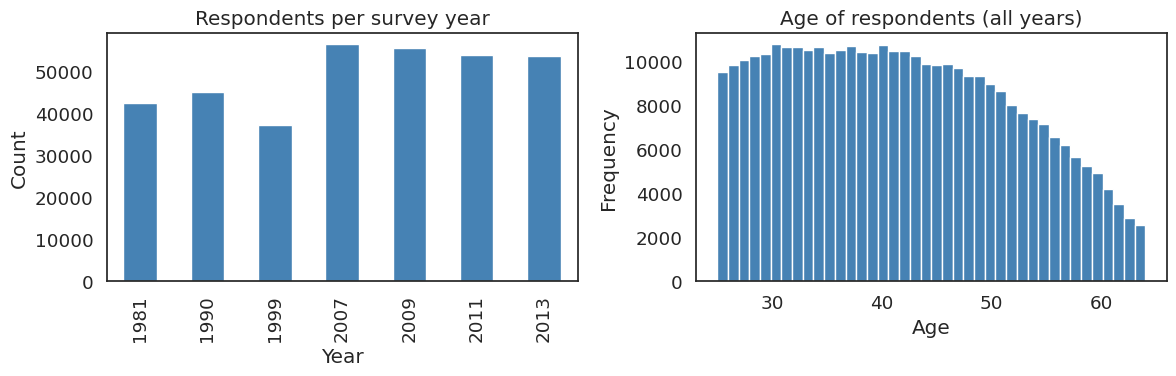

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cps["year"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Respondents per survey year", xlabel="Year", ylabel="Count")
cps["age"].plot.hist(bins=40, ax=axes[1], color="steelblue", edgecolor="white")
axes[1].set(title="Age of respondents (all years)", xlabel="Age")
plt.tight_layout()
plt.show()

### Exercise: who is in the sample, and who isn't?

Using the table and plots above, plus the CPS [methodology page](https://www.census.gov/programs-surveys/cps/technical-documentation/methodology.html):

1. Nobody in this file is under 25 or over 64, and everyone has **positive wage income**. So what is the *population* this sample can speak about? Is it "Americans"? "American workers"?
2. Who is systematically missing (think: students, retirees, the unemployed, the self-employed, people without a fixed address)?
3. Suppose a journalist uses this file to report "the average American earns \$X". What's wrong with that sentence?
4. How is the CPS sample drawn in the first place? Where could selection bias still creep in even with a random design (hint: who *answers* a survey)?

*Write your answers in the markdown cell below.*

**1. What population can this sample speak about?**
Only U.S. wage and salary earners aged 25 to 64 with positive wage income, living in ordinary households (the CPS samples housing units, so people in prisons, nursing homes or barracks aren't covered). It isn't "Americans", and it isn't even all "American workers": younger and older workers and anyone who works without a wage are left out.

**2. Who is systematically missing?**
- Students and young workers (under 25) and most retirees (over 64).
- The unemployed and people outside the labour force, e.g. carers and discouraged workers (they have zero wage income).
- The self-employed: business or farm income isn't wage income, so a self-employed person with no wages drops out.
- People without a fixed address and people living in institutions, because the survey samples addresses.
- Hard-to-reach groups who are less likely to take part, e.g. some undocumented immigrants.

**3. "The average American earns \$X"**
- Wrong population: this file is 25 to 64-year-old wage earners, not all Americans. The groups that are excluded (children, retirees, the unemployed) would mostly pull the figure down.
- Wrong statistic: "average" normally means the mean, and income is right-skewed, so a few very high earners pull the mean up. The median describes a typical person much better.
- It also needs a year and a unit: annual wage income, before tax, in 2013.

**4. How is the CPS drawn, and where can bias still creep in?**
The CPS is a multistage, stratified probability sample of roughly 60,000 households a month, drawn from a list of addresses based on the Census. Households are interviewed for 4 months, rest for 8, then return for 4 more. Even with a random design, bias can creep in through:
- **Non-response:** people who refuse or can't be reached (very busy, very rich, very poor, frequently moving) may differ from those who answer, and response rates have been falling.
- **Coverage:** the address list misses the homeless and people in institutions.
- **Self-report and proxy error:** one household member often answers for everyone, and incomes get rounded or misremembered.
- **Item non-response:** people who skip the income question get a value imputed by the Census Bureau.

## 2. Summary statistics

We'll focus on the most recent survey wave, **2013**. `describe()` gives the count, mean, standard deviation, min/max and quartiles (the 50% quartile is the **median**) of every numeric column.

In [67]:
df = cps[cps["year"] == 2013].copy()
df["income"] = df["incwage"] / 1000   # income in $ thousands: easier to read
df.describe().round(2)

,year,state,age,sex,race,sch,ind,union,incwage,realhrwage,income
count,53790.0,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00,53790.00
mean,2013.0,27.89,42.91,1.49,1.69,13.93,6363.97,0.19,51821.86,24.38,51.82
std,0.0,16.09,10.56,0.50,1.02,2.74,2612.37,0.46,60163.45,151.90,60.16
min,2013.0,1.00,25.00,1.00,1.00,0.00,170.00,0.00,38.00,2.01,0.04
25%,2013.0,12.00,34.00,1.00,1.00,12.00,4870.00,0.00,24000.00,12.17,24.00
50%,2013.0,27.00,43.00,1.00,1.00,13.00,7380.00,0.00,40000.00,18.44,40.00
75%,2013.0,42.00,51.00,2.00,3.00,16.00,8190.00,0.00,63000.00,28.12,63.00
max,2013.0,56.00,64.00,2.00,4.00,18.00,9590.00,3.00,1102999.00,34760.80,1103.00


### Exercise

From the table above:

1. What is the median hourly wage (`realhrwage`)? And the mean? Why are they different?
2. What is the average age?
3. Are there more men or women? (Hint: `sex` is 1 or 2, so its mean tells you the share of women... how?)
4. Interpret the mean of the `race` column. Does it mean anything?

1. The **median** hourly wage is **\$18.44** and the **mean** is **\$24.38**. They differ because hourly wages are right-skewed: a few very large (and some implausible, the max is \$34,760.80 an hour) values pull the mean up, while the median only depends on the middle person.
2. The average age is **42.91** years.
3. The mean of `sex` is **1.49**. Since everyone is coded 1 (male) or 2 (female), mean minus 1 = share of women = **0.494**, so about 49.4% women and 50.6% men: slightly **more men**.
4. The mean of `race` (1.69) **means nothing**. The codes 1 to 4 are labels, not quantities: nobody is "1.69", and renumbering the categories would change the mean. For a categorical variable we should report the mode instead (1 = White non-Hispanic, 34,662 of 53,790 people, about 64%).

### Categorical variables: use the mode

`race`, `sex`, `union` and `occupation` are **categorical**: the numbers are labels, not quantities, so their mean is meaningless. For categorical variables the most representative value is the **mode** (the most common category). Telling pandas a column is categorical stops it from computing nonsense:

In [68]:
for col in ["race", "sex", "union"]:
    df[col] = df[col].astype("category")

df["race"].describe()   # count, number of unique values, top (= mode) and its frequency

,race
count,53790
unique,4
top,1
freq,34662


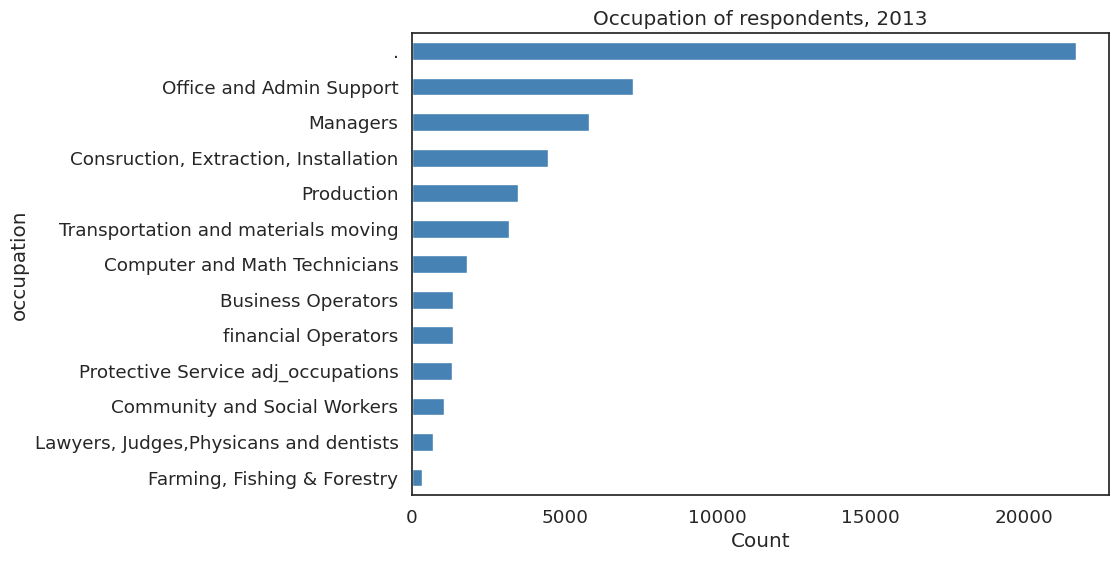

In [69]:
occ = df["occupation"].value_counts()
occ.sort_values().plot.barh(color="steelblue", figsize=(9, 6))
plt.title("Occupation of respondents, 2013")
plt.xlabel("Count")
plt.show()

### Exercise

1. What is the modal (most common) occupation? Be careful: what does the `.` category mean, and should it count?
2. Roughly what share of 2013 respondents have a missing occupation? If people with a missing occupation differ systematically from the rest (e.g. they earn less), what happens to any analysis that silently drops them?

In [70]:
# 1. Modal occupation
occ = df["occupation"].value_counts()
print(occ.head(4))
missing = df["occupation"].astype(str).str.strip() == "."
print("Mode if '.' is counted:", repr(occ.index[0]))
occ_known = df.loc[~missing, "occupation"].value_counts()
print("Mode among known occupations:", occ_known.index[0], "(", occ_known.iloc[0], "people )")

# 2. Share with a missing occupation, and are they different?
print("Share of 2013 respondents with missing occupation:", round(missing.mean(), 3))
print(df.groupby(missing)[["income", "age", "sch"]].median().rename(index={False: "known occupation", True: "missing ('.')"}))

# Answers
# 1. If '.' is counted, the "mode" is '.' (21,700 people), but '.' means MISSING, not an occupation, so it shouldn't count.
#    The modal real occupation is Office and Admin Support (7,240 people).
# 2. About 40% (0.403) of 2013 respondents have a missing occupation. They are not a random subset: their median income
#    is $35k vs $42k for people with a known occupation. Silently dropping them throws away 40% of the data and leaves a
#    better-paid group, so income estimates would be biased upwards and wouldn't describe the full sample.

occupation
.                                        21700
Office and Admin Support                  7240
Managers                                  5794
Consruction, Extraction, Installation     4462
Name: count, dtype: int64
Mode if '.' is counted: '.'
Mode among known occupations: Office and Admin Support ( 7240 people )
Share of 2013 respondents with missing occupation: 0.403
                  income   age   sch
occupation                          
known occupation    42.0  43.0  13.0
missing ('.')       35.0  42.0  14.0


### Mean vs median: skewed distributions

Income is the classic **skewed** variable: most people earn a moderate amount, a few earn a lot. Let's plot its distribution with a **histogram** and mark the mean and median.

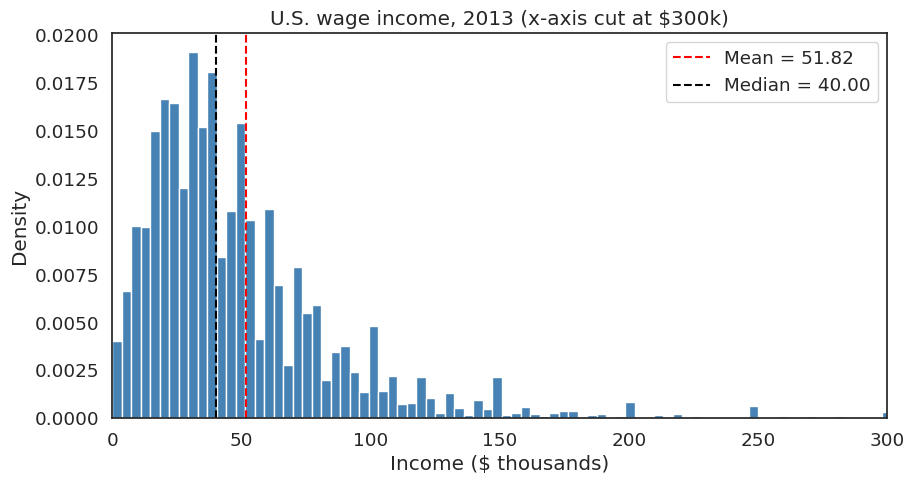

In [71]:
def plot_histogram(variable, bins=50, xlab="", title="", xlim=None):
    # Histogram of a pandas Series with its mean and median marked
    plt.hist(variable, bins=bins, edgecolor="white", density=True, color="steelblue")
    plt.axvline(variable.mean(), color="red", linestyle="--", label=f"Mean = {variable.mean():.2f}")
    plt.axvline(variable.median(), color="black", linestyle="--", label=f"Median = {variable.median():.2f}")
    if xlim is not None:
        plt.xlim(xlim)
    plt.xlabel(xlab)
    plt.ylabel("Density")
    plt.title(title)
    plt.legend()
    plt.show()

plot_histogram(df["income"], bins=300, xlab="Income ($ thousands)",
               title="U.S. wage income, 2013 (x-axis cut at $300k)", xlim=(0, 300))

### Exercise

1. Why is the mean larger than the median? Interpret this in terms of income inequality.
2. There are spikes at round numbers (\$50k, \$100k, \$150k ...). Is that because employers love round salaries, or because of *how the data were collected*? What does this tell you about self-reported survey data?
3. **Outliers.** Run the cell below, which adds a single person earning \$1 billion to the data. How much do the mean and the median move?

In [72]:
with_billionaire = pd.concat([df["income"], pd.Series([1_000_000])])   # $1bn = 1,000,000 thousand
print("Mean   before/after:", round(df["income"].mean(), 2), "/", round(with_billionaire.mean(), 2))
print("Median before/after:", round(df["income"].median(), 2), "/", round(with_billionaire.median(), 2))

# Answers
# 1. Income is right-skewed: most people earn moderate amounts but a few earn a lot, and those big values pull the mean
#    ($51.8k) above the median ($40k). Most workers earn less than the "average", which is a simple sign of inequality.
# 2. The spikes come from how the data were collected: people self-report their income and round it to a nice number
#    ("about 50k"). Self-reported survey data contain rounding (heaping) and recall error, so exact values need caution.
# 3. One $1bn earner moves the mean from $51.82k to $70.41k (up $18.6k, about 36%), while the median stays at $40k.
#    The median is robust to outliers; the mean is not.

Mean   before/after: 51.82 / 70.41
Median before/after: 40.0 / 40.0


### Spot the problem: the \$34,000-an-hour worker

A colleague sends you this summary and writes: *"The average American worker earns \$24.38 an hour."*

In [73]:
df["realhrwage"].describe().round(2)

,realhrwage
count,53790.00
mean,24.38
std,151.90
min,2.01
25%,12.17
50%,18.44
75%,28.12
max,34760.80


### Exercise

1. Look at the maximum. Is that plausible for a survey of wage earners? Find that person's row (hint: `df.sort_values("realhrwage").tail()`), and compare their hourly wage with their annual `income`.
2. Recompute the mean hourly wage *without* the top row. How much did one row move the mean? And the median?
3. Rewrite your colleague's sentence so that it is honest about (a) the population and (b) the choice of summary statistic.

In [74]:
# 1. Who is the $34,000-an-hour worker?
print(df.sort_values("realhrwage").tail()[["age", "sex", "sch", "occupation", "incwage", "realhrwage"]])
top = df["realhrwage"].idxmax()
print("Their annual wage income:", df.loc[top, "incwage"], "| hourly wage:", round(df.loc[top, "realhrwage"], 2))
print("Implied hours worked per year (income / hourly wage):", round(df.loc[top, "incwage"] / df.loc[top, "realhrwage"], 2))

# 2. Drop that one row and recompute
no_top = df.drop(index=top)
print("Mean   with / without:", round(df["realhrwage"].mean(), 2), "/", round(no_top["realhrwage"].mean(), 2))
print("Median with / without:", round(df["realhrwage"].median(), 2), "/", round(no_top["realhrwage"].median(), 2))
print("SD     with / without:", round(df["realhrwage"].std(), 2), "/", round(no_top["realhrwage"].std(), 2))

# Answers
# 1. Not plausible. The top row says $34,760.80 an hour but only $400,000 a year, which implies roughly 11.5 hours of
#    work in a whole year. That's almost certainly a data error (e.g. hours recorded wrongly), not a real wage. The next
#    highest rows (about $960 to $1,660 an hour on $16k to $90k a year) look like errors too.
# 2. Dropping that single row moves the mean from $24.38 to $23.74 (down $0.64) and the SD from 151.9 to 25.3.
#    The median doesn't move at all ($18.44).
# 3. "Among U.S. wage and salary earners aged 25 to 64 in the 2013 CPS, the median hourly wage was $18.44.
#    (The mean, $24.38, is pulled up by a few extreme and probably erroneous values.)"

        age sex   sch                             occupation   incwage    realhrwage
196432   35   2  18.0                                      .   52000.0    958.918579
274001   45   2  12.0                                      .   16000.0   1278.558105
140033   32   1  13.0  Consruction, Extraction, Installation   63002.0   1510.344727
45372    45   1  12.0  Consruction, Extraction, Installation   90000.0   1659.666870
144149   45   1  16.0                                      .  400000.0  34760.796875
Their annual wage income: 400000.0 | hourly wage: 34760.8
Implied hours worked per year (income / hourly wage): 11.51
Mean   with / without: 24.38 / 23.74
Median with / without: 18.44 / 18.44
SD     with / without: 151.9 / 25.34


### Measures of spread: variance and standard deviation

The mean tells us where the centre is; the **standard deviation** tells us how far a typical observation is from it.

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2 \qquad s=\sqrt{s^2}$$

The lecture compared a high-SD sample A with a low-SD sample B. Here is a real version: incomes in two occupations.

In [75]:
x = df.loc[df["occupation"] == "Office and Admin Support", "income"]

# the formula, by hand
s2 = ((x - x.mean())**2).sum() / (len(x) - 1)
print("By hand:  variance =", round(s2, 2), " sd =", round(np.sqrt(s2), 2))
print("pandas:   variance =", round(x.var(), 2), " sd =", round(x.std(), 2))

By hand:  variance = 1386.43  sd = 37.23
pandas:   variance = 1386.43  sd = 37.23


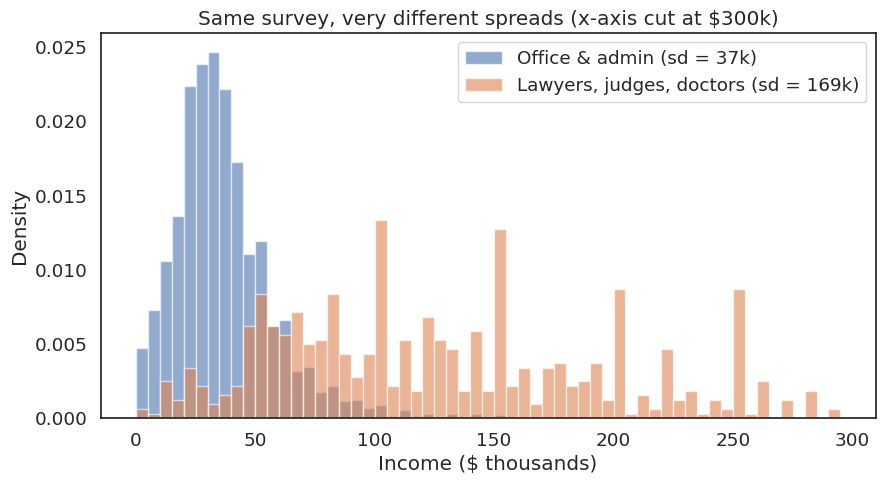

In [76]:
a = df.loc[df["occupation"] == "Lawyers, Judges,Physicans and dentists", "income"]
b = df.loc[df["occupation"] == "Office and Admin Support", "income"]

bins = np.arange(0, 300, 5)
plt.hist(b, bins=bins, density=True, alpha=0.6, label=f"Office & admin (sd = {b.std():.0f}k)")
plt.hist(a, bins=bins, density=True, alpha=0.6, label=f"Lawyers, judges, doctors (sd = {a.std():.0f}k)")
plt.xlabel("Income ($ thousands)"); plt.ylabel("Density")
plt.title("Same survey, very different spreads (x-axis cut at $300k)")
plt.legend(); plt.show()

### Exercise

1. Use `plot_histogram()` to plot the distribution of `age` (try 40 bins). Is it skewed? Does the mean differ much from the median?
2. Plot the distribution of years of schooling (`sch`). Pick a sensible number of bins, label it clearly, and explain the two big spikes.
3. For which of `income`, `age` and `sch` is the mean a good summary of a "typical" person? For which would you report the median?

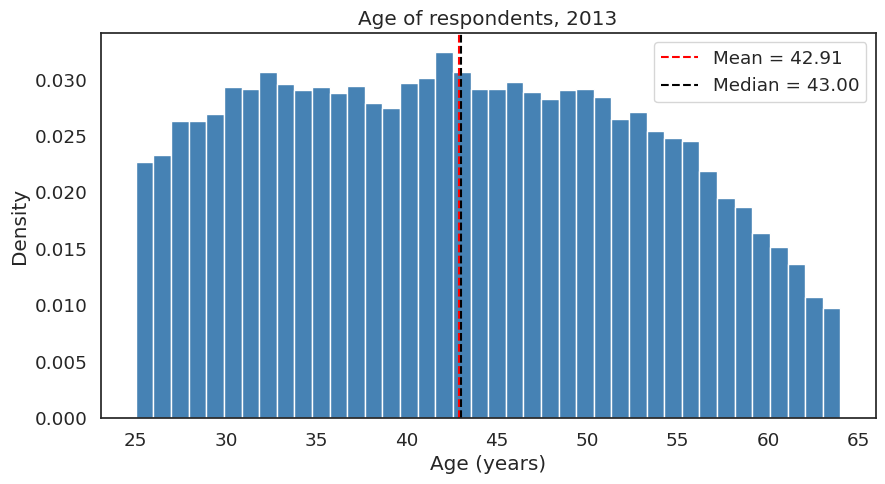

Age mean: 42.91 | median: 43.0 | skew: 0.104


In [77]:
# 1. Distribution of age
plot_histogram(df["age"], bins=40, xlab="Age (years)", title="Age of respondents, 2013")
print("Age mean:", round(df["age"].mean(), 2), "| median:", df["age"].median(), "| skew:", round(df["age"].skew(), 3))

# Answer 1: Age is barely skewed (skew = 0.10). It's fairly flat from 25 to about 55, then tails off towards 64.
#   The mean (42.91) and median (43) are almost identical.

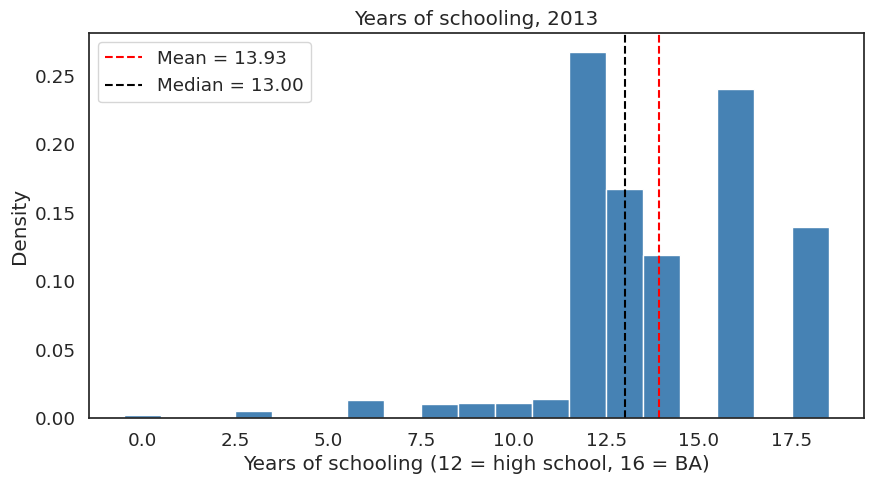

sch mean: 13.93 | median: 13.0 | mode: 12.0
{0.0: 0.2, 2.5: 0.5, 5.5: 1.3, 7.5: 1.1, 9.0: 1.1, 10.0: 1.1, 11.0: 1.4, 12.0: 26.8, 13.0: 16.7, 14.0: 11.9, 16.0: 24.0, 18.0: 14.0}
Skew  income: 8.86 | age: 0.1 | sch: -0.82


In [78]:
# 2. Distribution of years of schooling: one bar per whole year
plot_histogram(df["sch"], bins=np.arange(-0.5, 19.5, 1), xlab="Years of schooling (12 = high school, 16 = BA)",
               title="Years of schooling, 2013")
print("sch mean:", round(df["sch"].mean(), 2), "| median:", df["sch"].median(), "| mode:", df["sch"].mode()[0])
print((df["sch"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
print("Skew  income:", round(df["income"].skew(), 2), "| age:", round(df["age"].skew(), 2), "| sch:", round(df["sch"].skew(), 2))

# Answer 2: Two big spikes at 12 years (high school diploma, about 27% of people) and 16 years (bachelor's degree,
#   about a quarter), plus a smaller one at 18 (advanced degree). sch is coded from the highest qualification completed,
#   so people bunch at the points where a qualification ends. The distribution is left-skewed (skew = -0.82).
# Answer 3: Income is heavily right-skewed (skew 8.86), so report the MEDIAN. Age is roughly symmetric, so the MEAN is a
#   good summary. sch is lumpy and a bit left-skewed: its mean (13.9) isn't a level anyone actually has, so the median
#   (13) or the mode (12, high school) describes a typical person better.

Before moving on, we'll drop the small number of people earning over \$200k (about 1.6% of 2013 respondents), as in the lecture. This is a **choice**, and it changes the population we're describing (to "wage earners under \$200k"), so always report it.

In [79]:
print("Share of 2013 respondents earning over $200k:", round((df["income"] >= 200).mean(), 4))
df = df[df["income"] < 200]

Share of 2013 respondents earning over $200k: 0.0161


## 3. The Central Limit Theorem

### Estimating union membership in America

As in the lecture, let's ask: **what share of American workers are members of a labour union?**

The CPS only asks the union question to part of its sample (that's the `union = 0`, "N/A", group). So our **population** for this section is the 2013 respondents who were asked, and we create a binary variable: 1 = union member, 0 = not a member.

For the rest of the workshop we'll **pretend this group is the entire population**, so we know the true answer and can see how well samples recover it.

In [80]:
unions = df[df["union"] != 0].copy()
unions["member"] = (unions["union"] == 2).astype(int)

p = unions["member"].mean()
print(f"Population: {len(unions):,} people. True union membership rate: {p:.3f}")

Population: 8,697 people. True union membership rate: 0.141


### A sample of 7

Now imagine we can only afford to interview **7** random people. The code below draws one sample and computes its mean (= the share of union members in the sample). Run it several times.

In [81]:
sample = unions["member"].sample(7, replace=True)
print(sample.values, " -> sample mean:", round(sample.mean(), 3))

[1 0 0 0 0 0 0]  -> sample mean: 0.143


Quite often, *nobody* in the sample is a union member, so our estimate would be **0%**. How often? If each person has a probability $p$ of being a member, the chance that all 7 are not is $(1-p)^7$. Let's check that against a simulation of 10,000 samples.

The function below uses a `for` loop. Each time round the loop, it takes one random sample of `n` people (just like the cell above), computes the mean, and adds it to a list.

In [82]:
def sample_means(values, n, reps=10_000):
    # Take `reps` random samples of n people and return the mean of each one
    means = []
    for i in range(reps):
        sample = values.sample(n, replace=True)
        means.append(sample.mean())
    return np.array(means)

means7 = sample_means(unions["member"], n=7)
print("Theory:     P(all 7 are non-members) =", round((1 - p)**7, 3))
print("Simulation: share of samples with mean 0 =", round((means7 == 0).mean(), 3))

Theory:     P(all 7 are non-members) = 0.344
Simulation: share of samples with mean 0 = 0.345


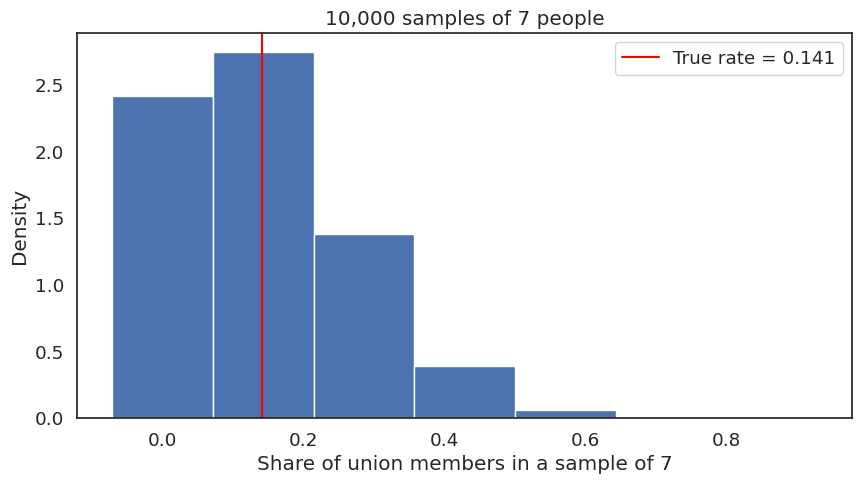

In [83]:
plt.hist(means7, bins=np.arange(-1/14, 1, 1/7), edgecolor="white", density=True)
plt.axvline(p, color="red", label=f"True rate = {p:.3f}")
plt.xlabel("Share of union members in a sample of 7")
plt.ylabel("Density")
plt.title("10,000 samples of 7 people")
plt.legend(); plt.show()

### Exercise

1. With samples of 7, what is the range of estimates you could plausibly get? Would you trust a single one?
2. Using the formula $(1-p)^n$, how likely is a sample of **1,000** people with *zero* union members? Now simulate it.
3. The lecture asked: "but *how* unlikely?" Answering that precisely is what the Central Limit Theorem is for.

In [84]:
# 1. Range of estimates from samples of 7
print("Possible sample means:", np.unique(means7).round(3))
print("Share of samples giving each estimate:", pd.Series(means7).round(3).value_counts(normalize=True).sort_index().round(3).to_dict())
print("Middle 95% of estimates:", np.percentile(means7, [2.5, 97.5]).round(3))

# 2. A sample of 1,000 with zero union members
print("Theory: P(all 1000 are non-members) =", (1 - p) ** 1000)
means1000 = sample_means(unions["member"], n=1000)
print("Simulation: share of 10,000 samples with mean 0 =", (means1000 == 0).mean())
print("Lowest sample mean in 10,000 samples of 1000:", means1000.min(), "| highest:", means1000.max())

# Answers
# 1. With n = 7 the estimate can only be 0%, 14.3%, 28.6%, 42.9%, ... Most samples give 0% (34.5% of samples),
#    14.3% (39.3%) or 28.6% (19.7%), and the middle 95% runs from 0% to 42.9%, against a true rate of 14.1%.
#    A single sample of 7 is close to useless: it often says "nobody is in a union" or "over a quarter are".
# 2. (1 - 0.141)^1000 is about 6.8e-67, i.e. essentially impossible. In 10,000 simulated samples of 1,000, none had
#    zero members; the sample means only ranged from 9.9% to 18.4%.

Possible sample means: [0.    0.143 0.286 0.429 0.571 0.714 0.857]
Share of samples giving each estimate: {0.0: 0.345, 0.143: 0.393, 0.286: 0.197, 0.429: 0.056, 0.571: 0.008, 0.714: 0.001, 0.857: 0.0}
Middle 95% of estimates: [0.    0.429]
Theory: P(all 1000 are non-members) = 6.836584757279598e-67
Simulation: share of 10,000 samples with mean 0 = 0.0
Lowest sample mean in 10,000 samples of 1000: 0.099 | highest: 0.184


### The sampling distribution becomes normal

The distribution of sample means is called the **sampling distribution**. Watch what happens to it as the sample size grows. The black curve is a normal distribution with the same mean and standard deviation as the simulated means.

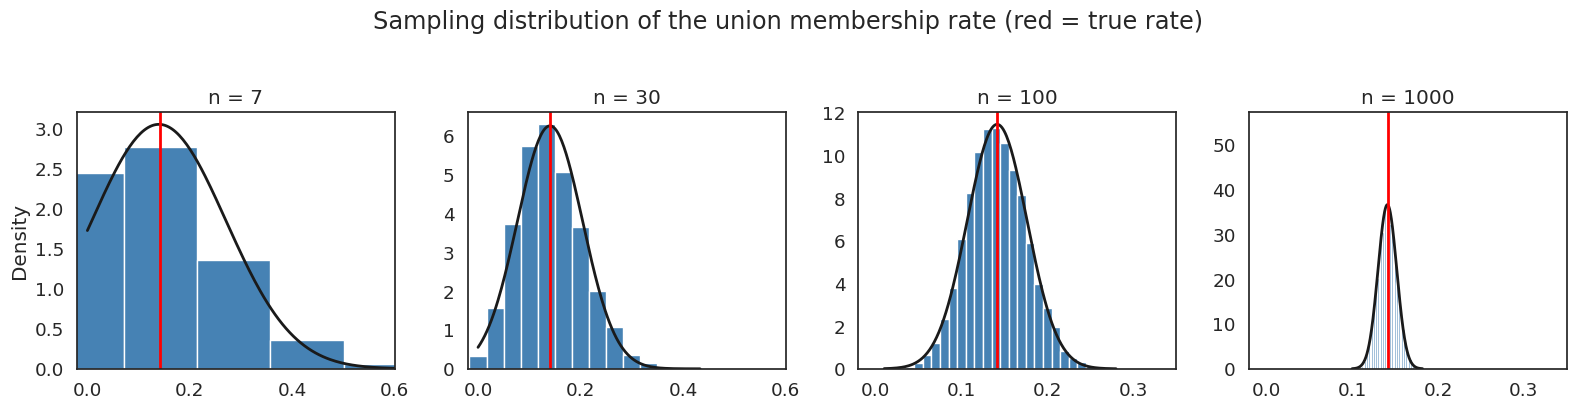

In [85]:
def plot_sampling_distribution(means, ax, true_mean, title, n=None):
    # For a 0/1 variable the sample mean can only take the values 0, 1/n, 2/n, ...
    # so if n is given (and small) we use one bar per possible value.
    bins = (np.arange(n + 2) - 0.5) / n if (n is not None and n <= 200) else 40
    ax.hist(means, bins=bins, density=True, color="steelblue", edgecolor="white")
    mu, sd = means.mean(), means.std()
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, norm.pdf(xs, mu, sd), "k", lw=2)
    ax.axvline(true_mean, color="red", lw=2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, n in zip(axes, [7, 30, 100, 1000]):
    plot_sampling_distribution(sample_means(unions["member"], n), ax, p, f"n = {n}", n=n)
    ax.set_xlim(-0.02, 0.6 if n < 100 else 0.35)
axes[0].set_ylabel("Density")
fig.suptitle("Sampling distribution of the union membership rate (red = true rate)", y=1.03)
plt.tight_layout(); plt.show()

The underlying variable is just 0s and 1s, as far from a bell curve as it gets. Yet with big enough samples the **sample means** are approximately normal and centred on the true value. That is the **Central Limit Theorem**:

> If you take sufficiently large random samples, the distribution of sample means is approximately normal, *regardless of the distribution of the underlying population*.

### It works for skewed variables too

Income is heavily right-skewed. Compare the distribution of individual incomes (left) with the distribution of the means of samples of 500 people (right).

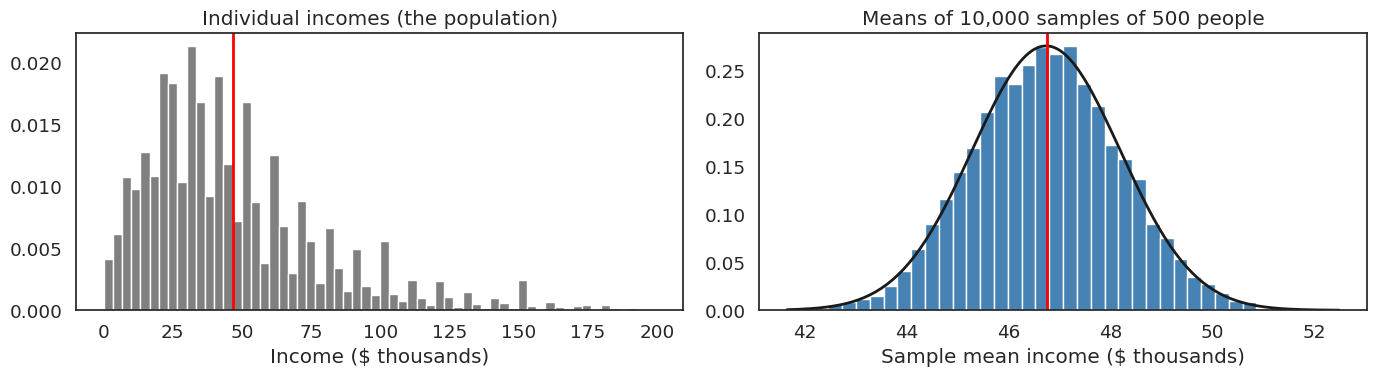

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["income"], bins=60, density=True, color="grey", edgecolor="white")
axes[0].axvline(df["income"].mean(), color="red", lw=2)
axes[0].set(title="Individual incomes (the population)", xlabel="Income ($ thousands)")
plot_sampling_distribution(sample_means(df["income"], 500), axes[1], df["income"].mean(),
                           "Means of 10,000 samples of 500 people")
axes[1].set_xlabel("Sample mean income ($ thousands)")
plt.tight_layout(); plt.show()

### Exercise

1. Repeat the two-panel plot for `age` and for `sch` (years of schooling). How non-normal are the raw distributions? Are the sampling distributions normal?
2. Try a small sample size (e.g. n = 5) for income. At what sample size does the sampling distribution start to look normal? Is it the same for a symmetric variable like age?

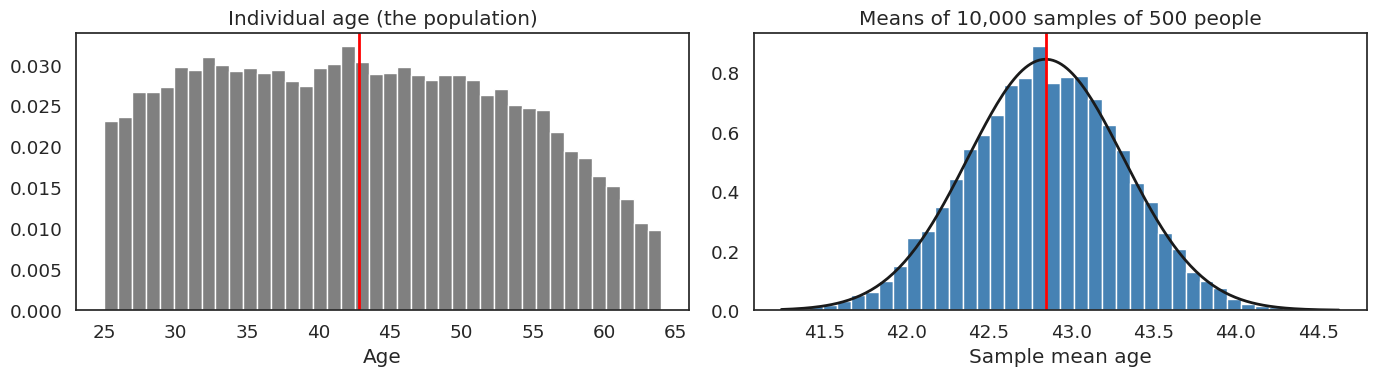

age: skew of raw data = 0.11, skew of sample means = -0.029


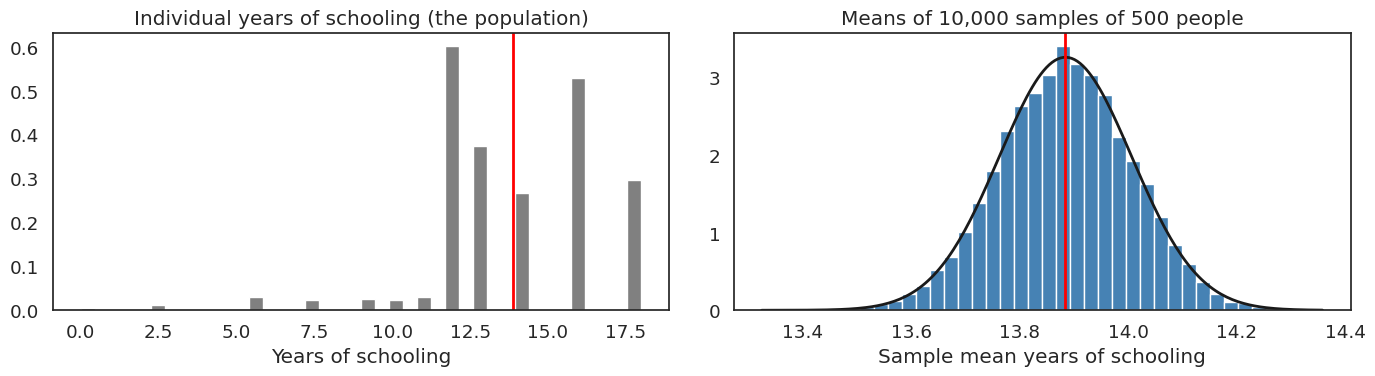

sch: skew of raw data = -0.83, skew of sample means = -0.033
income, n = 5: skew of sample means = 0.632
age, n = 5: skew of sample means = 0.066
income, n = 30: skew of sample means = 0.253
age, n = 30: skew of sample means = 0.019
income, n = 100: skew of sample means = 0.118
age, n = 100: skew of sample means = 0.005


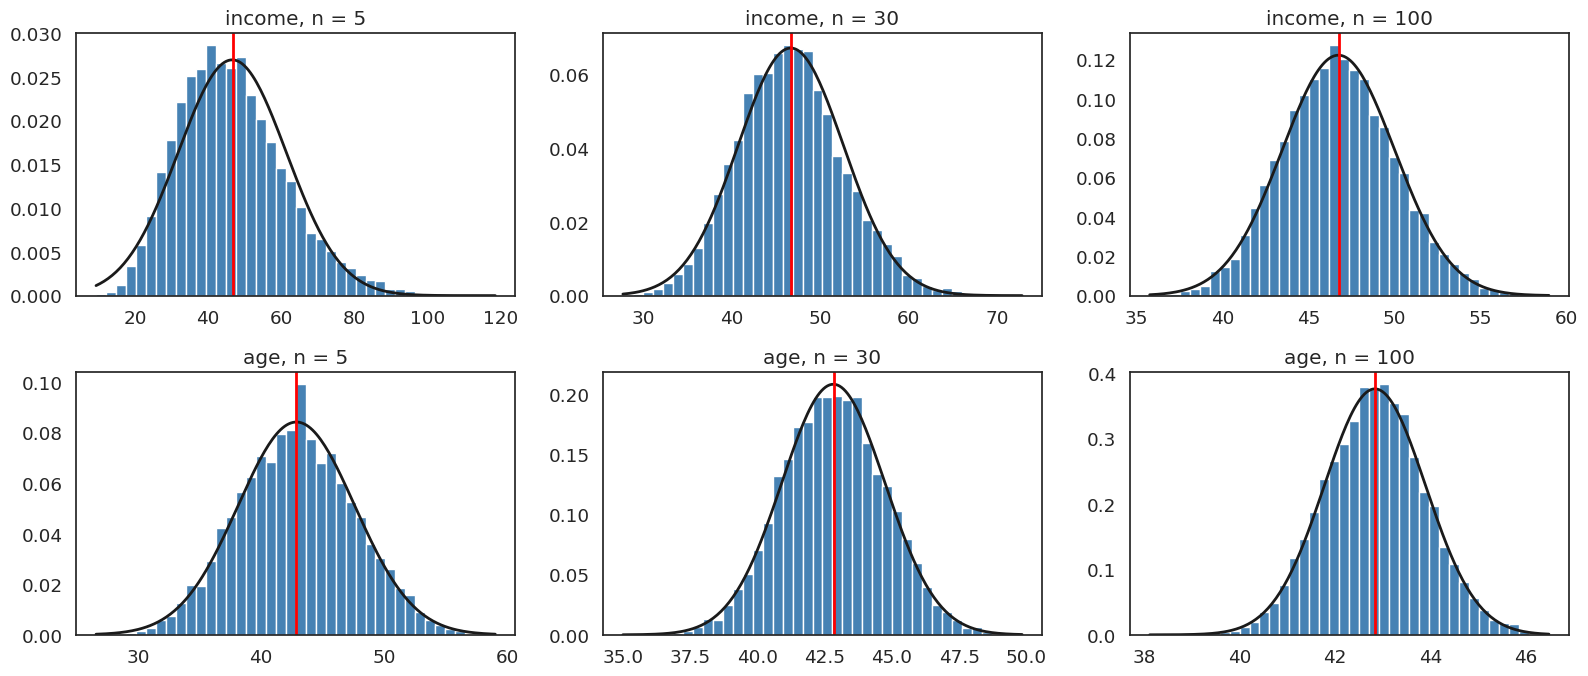

In [87]:
from scipy.stats import skew

# 1. Two-panel plots for age and years of schooling (samples of 500)
for var, lab in [("age", "Age"), ("sch", "Years of schooling")]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(df[var], bins=40, density=True, color="grey", edgecolor="white")
    axes[0].axvline(df[var].mean(), color="red", lw=2)
    axes[0].set(title=f"Individual {lab.lower()} (the population)", xlabel=lab)
    m = sample_means(df[var], 500)
    plot_sampling_distribution(m, axes[1], df[var].mean(), "Means of 10,000 samples of 500 people")
    axes[1].set_xlabel(f"Sample mean {lab.lower()}")
    plt.tight_layout(); plt.show()
    print(f"{var}: skew of raw data = {df[var].skew():.2f}, skew of sample means = {skew(m):.3f}")

# 2. Small samples: when does the sampling distribution look normal?
sizes = [5, 30, 100]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for j, n in enumerate(sizes):
    for i, var in enumerate(["income", "age"]):
        m = sample_means(df[var], n)
        plot_sampling_distribution(m, axes[i, j], df[var].mean(), f"{var}, n = {n}")
        print(f"{var}, n = {n}: skew of sample means = {skew(m):.3f}")
plt.tight_layout(); plt.show()

# Answers
# 1. Raw age is fairly flat (skew 0.11) and sch is lumpy with spikes at 12 and 16 (skew -0.83); neither looks normal.
#    But the means of samples of 500 are bell-shaped and centred on the true mean for both (skew of sample means ~ -0.03).
# 2. For income, at n = 5 the sampling distribution is still clearly right-skewed (skew 0.63); by n = 30 it is close to
#    normal with a slight right tail (0.25); by n = 100 it looks normal (0.12). For a fairly symmetric variable like age
#    it already looks normal at n = 5 (skew 0.07). So "large enough" depends on how skewed the underlying variable is.

### The standard error

The standard deviation of the sampling distribution is called the **standard error** (SE). It tells us how far a sample mean typically lands from the population mean:

$$SE = \frac{\sigma}{\sqrt{n}}$$

where $\sigma$ is the population standard deviation and $n$ is the sample size. Because the sampling distribution is normal, the **68-95-99.7 rule** applies: about 68%, 95% and 99.7% of sample means land within 1, 2 and 3 SEs of the population mean. Let's check it for samples of 1,000. (Next week we look at the standard error in more detail.)

In [88]:
n = 1000
se = unions["member"].std() / np.sqrt(n)
means = sample_means(unions["member"], n)

print("Standard error:", round(se, 4))
print("Share within 1 SE:", (abs(means - p) < 1 * se).mean())
print("Share within 2 SE:", (abs(means - p) < 2 * se).mean())
print("Share within 3 SE:", (abs(means - p) < 3 * se).mean())

Standard error: 0.011
Share within 1 SE: 0.6871
Share within 2 SE: 0.9589
Share within 3 SE: 0.9981


# Assessed Question

The URL below contains the 2013 CPS respondents: one row per person, with the same columns as the `cps` dataframe we used above.

https://oballinger.github.io/BASC0005/data/assessed/w05_cps_2013.csv

Note that the file may have been corrupted; some values or labels may be wrong, so make sure to sense-check your data before answering.

**QUESTION: Treat all 2013 respondents with a reported wage income (incwage > 0) as the population. Using SE = sigma/sqrt(n) and the 68-95-99.7 rule, what is the smallest sample size n such that 95% of sample means fall within $1,000 of the population mean income? Use .std() for sigma.**

In [89]:
import math
w05 = pd.read_csv("https://oballinger.github.io/BASC0005/data/assessed/w05_cps_2013.csv")

# 1. Sense-check against the clean 2013 class data: which columns differ?
orig = cps[cps["year"] == 2013].reset_index(drop=True)
for col in w05.columns:
    n_diff = (w05[col] != orig[col]).sum()
    if n_diff:
        print(f"{col}: {n_diff} values differ")
print("Corrupted incwage values:", w05.loc[w05["incwage"] != orig["incwage"], "incwage"].unique())
print("incwage max:", w05["incwage"].max(), "| std with the bad values left in:", round(w05["incwage"].std(), 1))
# -> 1,613 incomes (3%) were replaced with 99,999,999: a 'missing / not in universe' code, not a real wage.
#    Everything else is identical to the class data.

# 2. Fix: treat the code as missing, then keep reported wage incomes (incwage > 0) as the population
w05["incwage"] = w05["incwage"].replace(99_999_999, np.nan)
pop = w05.loc[w05["incwage"] > 0, "incwage"]
sigma = pop.std()

# 3. 68-95-99.7 rule: 95% of sample means lie within 2 SE of the population mean.
#    Need 2 * sigma / sqrt(n) <= 1000   ->   n >= (2 * sigma / 1000)^2
n_exact = (2 * sigma / 1000) ** 2
n_min = math.ceil(n_exact)
print(f"Population N = {len(pop):,} | mean = {pop.mean():,.2f} | sigma = {sigma:,.2f}")
print(f"(2 * sigma / 1000)^2 = {n_exact:,.2f}")
print("ANSWER: smallest n =", n_min)
print("Check: 2 SE at n =", round(2 * sigma / np.sqrt(n_min), 2), "| at n - 1 =", round(2 * sigma / np.sqrt(n_min - 1), 2))
# Without the fix, sigma is about $17m and n would be over 1.1 billion: impossible for a population of ~54,000.

incwage: 1613 values differ
Corrupted incwage values: [99999999.]
incwage max: 99999999.0 | std with the bad values left in: 17046558.7
Population N = 52,177 | mean = 51,824.98 | sigma = 60,190.41
(2 * sigma / 1000)^2 = 14,491.54
ANSWER: smallest n = 14492
Check: 2 SE at n = 999.98 | at n - 1 = 1000.02


## Recap

1. A **population** is the set of all relevant measurements; a **sample** is the part we observe. Always ask how the sample was selected: this CPS extract only covers 25-64 year-old wage earners.
2. Use the **median** for skewed variables, the **mode** for categorical ones, and check extreme values before trusting a mean.
3. **Central Limit Theorem:** for sufficiently large random samples, sample means are approximately normally distributed, whatever the shape of the underlying data.
4. The **standard error** $\sigma/\sqrt{n}$ tells us how much a sample mean bounces around; about 95% of sample means fall within 2 SEs of the population mean.

Next week we look at the **standard error** in more detail, turn it into **confidence intervals** and **hypothesis tests**, and meet a Bayesian way to estimate union membership.